# Adversarial Search: Solving Tic-Tac-Toe with Heuristic Alpha-Beta Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. __Heuristic Alpha-Beta Tree Search:__ Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Heuristic Alpha-Beta Tree Search

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [ ]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [1]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Heuristic Alpha-Beta Tree Search

See AIMA page 156ff. 


## Heuristic Evaluation Function

In [2]:
import numpy as np

def eval_fun(state, player = 'x'):
    """heuristic for utility of state. Returns score for a node:
    1. For terminal states it returns the utility. 
    2. For non-terminal states, it calculates a weighted linear function using features of the state. 
    The features we look at are 2 in a row/col/diagonal where the 3rd square is empty. We assume that
    the more of these positions we have, the higher the chance of winning.
    We need to be careful that the utility of the heuristic stays between [-1,1]. 
    Note that the largest possible number of these positions is 2. I weigh the count by 0.4, 
    guaranteeing that is in the needed range.
    
    Function Returns: heuristic value, terminal?"""
    
    # terminal state?
    u = utility(state, player)
    if u is not None: return u, True
      
    score = 0
    board = np.array(state).reshape((3,3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], 
                          [board[i][len(board)-i-1] for i in range(len(board))]])
    
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row ==' '): score += .4
            if sum(row == other(player)) == 2 and any(row ==' '): score -= .4
    
    return score, False

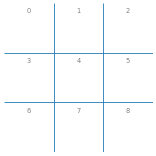

eval for x: (0, False)
eval for o: (0, False)


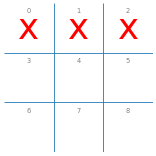

eval for x: (1, True)
eval for o: (-1, True)


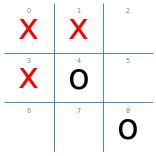

eval for x: (0.8, False)
eval for o: (-0.8, False)


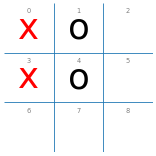

eval for x: (0.0, False)
eval for o: (0.0, False)


In [3]:
board = empty_board() 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[2] = 'x' 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[3] = 'x' 
board[4] = 'o'
board[8] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'x' 
board[4] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

## Search with Cutoff

We add a cutoff to the Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning (see AIMA page 156ff). We use the heuristic evaluation function and the back-up the value using minimax search with alpha-beta pruning to determine the next move.

In [4]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, cutoff = None, player = 'x'):
    """start the search. cutoff = None is minimax search with alpha-beta pruning."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}") 
    
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


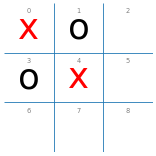


Number of nodes searched (cutoff = 2): 13


{'move': 8, 'value': 1}

CPU times: total: 0 ns
Wall time: 5.82 ms

Number of nodes searched (cutoff = 4): 47


{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 9.35 ms

Number of nodes searched (cutoff = None): 61


{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 11.1 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))

print()
%time display(alpha_beta_search(board, 4))

print()
%time display(alpha_beta_search(board))

### o is about to win

Board:


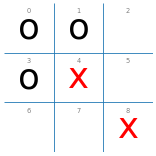


Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 3.79 ms

Number of nodes searched (cutoff = None): 15


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 5.27 ms


In [6]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board))

### x can draw if it chooses 7

Board:


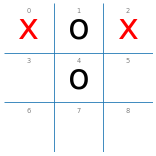


Number of nodes searched (cutoff = 2): 21


{'move': 7, 'value': -0.4}

CPU times: total: 15.6 ms
Wall time: 4.8 ms

Number of nodes searched (cutoff = 4): 81


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 16.8 ms

Number of nodes searched (cutoff = None): 101


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 15 ms


In [7]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


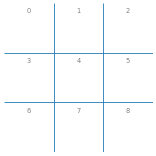


Number of nodes searched (cutoff = 2): 26


{'move': 0, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 7.75 ms

Number of nodes searched (cutoff = 4): 541


{'move': 4, 'value': 0.0}

CPU times: total: 78.1 ms
Wall time: 90.6 ms

Number of nodes searched (cutoff = None): 18297


{'move': 0, 'value': 0}

CPU times: total: 2.14 s
Wall time: 2.23 s


In [8]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### A bad situation

Board:


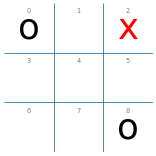


Number of nodes searched (cutoff = 2): 29


{'move': 4, 'value': -0.8}

CPU times: total: 0 ns
Wall time: 6.87 ms

Number of nodes searched (cutoff = 4): 148


{'move': 1, 'value': -1}

CPU times: total: 31.2 ms
Wall time: 27.9 ms

Number of nodes searched (cutoff = None): 238


{'move': 1, 'value': -1}

CPU times: total: 46.9 ms
Wall time: 38.9 ms


In [9]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

In [10]:
import time
import pandas as pd

DEBUG = 0

# Cùng 4 trạng thái kiểm thử của Bài 3
test_cases = {
    "Case 1 - X can win": {
        0: 'x', 1: 'o', 3: 'o', 4: 'x'
    },
    "Case 2 - X can draw": {
        0: 'x', 1: 'o', 2: 'x', 4: 'o'
    },
    "Case 3 - Bad situation": {
        0: 'o', 2: 'x', 8: 'o'
    },
    "Case 4 - Empty board": {}
}

configurations = [
    ("Alpha-Beta Full", None),
    ("Heuristic AB - depth 2", 2),
    ("Heuristic AB - depth 4", 4)
]

results = []

for case_name, positions in test_cases.items():
    board = empty_board()

    for index, symbol in positions.items():
        board[index] = symbol

    for algorithm_name, depth in configurations:
        start = time.perf_counter()

        answer = alpha_beta_search(
            board,
            cutoff=depth,
            player='x'
        )

        elapsed = time.perf_counter() - start

        results.append({
            "Case": case_name,
            "Algorithm": algorithm_name,
            "Cutoff": "Full" if depth is None else depth,
            "Move": answer["move"],
            "Value": answer["value"],
            "Nodes": COUNT,
            "Time (s)": round(elapsed, 6)
        })

df = pd.DataFrame(results)
display(df)

,Case,Algorithm,Cutoff,Move,Value,Nodes,Time (s)
0,Case 1 - X can win,Alpha-Beta Full,Full,2,1.0,61,0.005809
1,Case 1 - X can win,Heuristic AB - depth 2,2,8,1.0,13,0.001480
2,Case 1 - X can win,Heuristic AB - depth 4,4,2,1.0,47,0.005580
3,Case 2 - X can draw,Alpha-Beta Full,Full,7,0.0,101,0.008891
4,Case 2 - X can draw,Heuristic AB - depth 2,2,7,-0.4,21,0.002229
5,Case 2 - X can draw,Heuristic AB - depth 4,4,7,0.0,81,0.009044
6,Case 3 - Bad situation,Alpha-Beta Full,Full,1,-1.0,238,0.024701
7,Case 3 - Bad situation,Heuristic AB - depth 2,2,4,-0.8,29,0.004653
8,Case 3 - Bad situation,Heuristic AB - depth 4,4,1,-1.0,148,0.024596
9,Case 4 - Empty board,Alpha-Beta Full,Full,0,0.0,18297,2.308676


In [11]:
import math

quality_results = []

for case_name, positions in test_cases.items():
    board = empty_board()

    for index, symbol in positions.items():
        board[index] = symbol

    full_result = alpha_beta_search(
        board, cutoff=None, player='x'
    )
    optimal_value = full_result["value"]

    for depth in [2, 4]:
        answer = alpha_beta_search(
            board, cutoff=depth, player='x'
        )

        chosen_move = answer["move"]

        # Đánh giá chính xác kết quả của nước đi đã chọn
        next_board = result(board, 'x', chosen_move)

        exact_value, _ = min_value_ab(
            next_board,
            'x',
            -math.inf,
            math.inf,
            1,
            None
        )

        quality_results.append({
            "Case": case_name,
            "Cutoff": depth,
            "Heuristic Move": chosen_move,
            "Estimated Value": answer["value"],
            "Exact Move Value": exact_value,
            "Optimal Value": optimal_value,
            "Optimal Move?": exact_value == optimal_value
        })

quality_df = pd.DataFrame(quality_results)
display(quality_df)

,Case,Cutoff,Heuristic Move,Estimated Value,Exact Move Value,Optimal Value,Optimal Move?
0,Case 1 - X can win,2,8,1.0,1,1,True
1,Case 1 - X can win,4,2,1.0,1,1,True
2,Case 2 - X can draw,2,7,-0.4,0,0,True
3,Case 2 - X can draw,4,7,0.0,0,0,True
4,Case 3 - Bad situation,2,4,-0.8,-1,-1,True
5,Case 3 - Bad situation,4,1,-1.0,-1,-1,True
6,Case 4 - Empty board,2,0,0.0,0,0,True
7,Case 4 - Empty board,4,4,0.0,0,0,True


### Nhận xét: So sánh Alpha-Beta đầy đủ và Heuristic Alpha-Beta

Qua thực nghiệm trên 4 trạng thái Tic-Tac-Toe, việc sử dụng hàm đánh giá heuristic kết hợp giới hạn độ sâu giúp giảm đáng kể số nút duyệt và thời gian tìm kiếm so với Alpha-Beta đầy đủ.

Ở Case 4 (bàn cờ trống), Alpha-Beta đầy đủ duyệt 18.297 nút với thời gian 2,309 giây, trong khi cutoff = 4 duyệt 541 nút trong 0,070 giây và cutoff = 2 chỉ duyệt 26 nút trong 0,005 giây. Điều này cho thấy giới hạn độ sâu giúp cải thiện đáng kể hiệu suất tìm kiếm.

Về chất lượng nước đi, kết quả kiểm tra cho thấy cả 8 nước đi của hai cấu hình heuristic đều đạt giá trị Minimax tối ưu. Tuy nhiên, giá trị ước lượng chưa phải lúc nào cũng chính xác. Ví dụ, ở Case 2, cutoff = 2 đánh giá -0,4 trong khi giá trị thực tế là 0. Tương tự, ở Case 3, giá trị ước lượng là -0,8 nhưng giá trị thực tế là -1.

Khi tăng cutoff từ 2 lên 4, thuật toán tìm kiếm sâu hơn, làm tăng số nút duyệt và nhìn chung tăng chi phí tính toán. Tuy nhiên, thời gian đo thực tế có thể dao động do chi phí thực thi và môi trường chạy.

Giá trị tối ưu của mỗi nước đi được xác minh bằng cách thực hiện tìm kiếm Alpha-Beta đầy đủ từ trạng thái sau nước đi đó. Do đó, kết quả đánh giá không chỉ dựa trên giá trị heuristic ước lượng.

Nhìn chung, Heuristic Alpha-Beta thể hiện sự đánh đổi giữa độ sâu tìm kiếm và hiệu suất tính toán. Cutoff nhỏ giúp tiết kiệm tài nguyên, trong khi cutoff lớn có thể cải thiện chất lượng đánh giá và giảm nguy cơ lựa chọn nước đi không tối ưu.

## Experiments



### Minimax with Alpha-Beta Pruning vs. Random

In [12]:
def heuristic2_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 2, player = player)["move"]

def heuristic4_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 4, player = player)["move"]

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = None, player = player)["move"]

DEBUG = 1
print("heuristic2 vs. random:")
display(play(heuristic2_player, random_player, N = 3))

heuristic2 vs. random:
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 27
Number of nodes searched (cutoff = 2): 10


{'x': 3, 'o': 0, 'd': 0}

In [13]:
DEBUG = 0
print("heuristic2 vs. random:")
%time display(play(heuristic2_player, random_player))

print("heuristic4 vs. random:")
%time display(play(heuristic4_player, random_player))

print()
print("random vs. heuristic2")
%time display(play(random_player, heuristic2_player))

print("random vs. heuristic4")
%time display(play(random_player, heuristic4_player))

heuristic2 vs. random:


{'x': 95, 'o': 0, 'd': 5}

CPU times: total: 1.14 s
Wall time: 1.16 s
heuristic4 vs. random:


{'x': 100, 'o': 0, 'd': 0}

CPU times: total: 14.2 s
Wall time: 14.7 s

random vs. heuristic2


{'x': 3, 'o': 88, 'd': 9}

CPU times: total: 1.11 s
Wall time: 1.13 s
random vs. heuristic4


{'x': 0, 'o': 84, 'd': 16}

CPU times: total: 12.6 s
Wall time: 13 s


### Nhận xét: Heuristic Alpha-Beta vs Random Agent

Qua 100 ván thi đấu với Random Agent, cả Heuristic 2 và Heuristic 4 đều đạt kết quả tốt. Khi đi trước với quân X, Heuristic 2 thắng 95 ván và hòa 5 ván, trong khi Heuristic 4 thắng cả 100 ván.

Khi đi sau với quân O, Heuristic 2 thắng 88 ván, hòa 9 ván và thua 3 ván. Heuristic 4 thắng 84 ván, hòa 16 ván và không thua ván nào.

Khi đi sau, Heuristic 4 không thua ván nào, trong khi Heuristic 2 thua 3 ván. Tuy nhiên, Heuristic 2 có số trận thắng cao hơn (88 so với 84). Điều này cho thấy Heuristic 4 tránh thua tốt hơn trong lần thực nghiệm này, nhưng chưa đủ để khẳng định mạnh hơn toàn diện.

Do Random Agent lựa chọn nước đi ngẫu nhiên, kết quả có thể thay đổi giữa các lần chạy. Vì vậy, cần thực hiện thêm nhiều thí nghiệm để đánh giá đáng tin cậy hơn sự khác biệt giữa hai tác tử.

### Heuristic vs. Minimax with Alpha-Beta Pruning

In [14]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. alpha_beta")
%time display(play(heuristic2_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic2")
%time display(play(alpha_beta_player, heuristic2_player, N = 1))

print()
print("heuristic4 vs alpha_beta")
%time display(play(heuristic4_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic4")
%time display(play(alpha_beta_player, heuristic4_player, N = 1))

heuristic2 vs. alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 578 ms
Wall time: 612 ms

alpha_beta vs. heuristic2


{'x': 1, 'o': 0, 'd': 0}

CPU times: total: 3.81 s
Wall time: 3.92 s

heuristic4 vs alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 1.05 s
Wall time: 1.11 s

alpha_beta vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 3.39 s
Wall time: 3.55 s


### Nhận xét: Heuristic Alpha-Beta vs Alpha-Beta đầy đủ

Qua thực nghiệm, Heuristic 2 hòa Alpha-Beta đầy đủ khi đi trước nhưng thua khi đi sau. Trong khi đó, Heuristic 4 đạt kết quả hòa ở cả hai trường hợp.

Kết quả cho thấy Heuristic 4 có khả năng duy trì kết quả tốt hơn Heuristic 2 trong các ván đấu được kiểm thử. Tuy nhiên, Heuristic 4 cần tìm kiếm sâu hơn nên có chi phí tính toán lớn hơn.

Thời gian thực thi mỗi ván dao động từ 0,612 đến 3,920 giây, tùy thuộc vào cấu hình tác tử và thứ tự đi trước. Do mỗi cặp chỉ thi đấu một ván từ bàn cờ trống, kết quả chưa đủ để kết luận toàn diện về sức mạnh của các thuật toán.

### Heuristic vs. Heuristic

In [15]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. heuristic4")
%time display(play(heuristic2_player, heuristic4_player, N = 1))

print()
print("heuristic4 vs. heuristic2")
%time display(play(heuristic4_player, heuristic2_player, N = 1))

heuristic2 vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 78.1 ms
Wall time: 89.3 ms

heuristic4 vs. heuristic2


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 172 ms
Wall time: 155 ms


### Nhận xét: Heuristic 2 vs Heuristic 4

Khi Heuristic 2 và Heuristic 4 thi đấu trực tiếp, cả hai ván đều kết thúc với kết quả hòa, bất kể tác tử nào đi trước.

Thời gian thực thi lần lượt là 0,089 giây khi Heuristic 2 đi trước và 0,155 giây khi Heuristic 4 đi trước. Sự khác biệt này phụ thuộc vào số lượng và độ phức tạp của các trạng thái được tìm kiếm trong từng ván.

Kết quả cho thấy cả hai tác tử đều có khả năng duy trì kết quả hòa trong các tình huống thử nghiệm. Mặc dù Heuristic 4 tìm kiếm sâu hơn, điều đó không tạo ra lợi thế rõ ràng về kết quả khi hai tác tử đối đầu từ bàn cờ trống.

__Idea:__ Start experiments with different boards that already have a few x's and o's randomly placed on them.